In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
airbnb_dataframe=pd.read_csv('input/listings.csv')


In [3]:
airbnb_dataframe.head()

,id,listing_url,scrape_id,last_scraped,name,summary,space,description,experiences_offered,neighborhood_overview,...,review_scores_value,requires_license,license,jurisdiction_names,instant_bookable,cancellation_policy,require_guest_profile_picture,require_guest_phone_verification,calculated_host_listings_count,reviews_per_month
0,7087327,https://www.airbnb.com/rooms/7087327,20151002231825,2015-10-03,Historic DC Condo-Walk to Capitol!,Professional pictures coming soon! Welcome to ...,NaN,Professional pictures coming soon! Welcome to ...,none,NaN,...,NaN,f,NaN,"DISTRICT OF COLUMBIA, WASHINGTON",f,flexible,f,f,18,NaN
1,975833,https://www.airbnb.com/rooms/975833,20151002231825,2015-10-03,Spacious Capitol Hill Townhouse,NaN,Beautifully renovated Capitol Hill townhouse. ...,Beautifully renovated Capitol Hill townhouse. ...,none,NaN,...,9.0,f,NaN,"DISTRICT OF COLUMBIA, WASHINGTON",f,strict,f,f,1,2.11
2,8249488,https://www.airbnb.com/rooms/8249488,20151002231825,2015-10-03,Spacious/private room for single,This is an ideal room for a single traveler th...,NaN,This is an ideal room for a single traveler th...,none,NaN,...,NaN,f,NaN,NaN,f,flexible,f,f,1,1.00
3,8409022,https://www.airbnb.com/rooms/8409022,20151002231825,2015-10-03,A wonderful bedroom with library,Prime location right on the Potomac River in W...,NaN,Prime location right on the Potomac River in W...,none,NaN,...,NaN,f,NaN,"DISTRICT OF COLUMBIA, WASHINGTON",f,flexible,f,f,1,NaN
4,8411173,https://www.airbnb.com/rooms/8411173,20151002231825,2015-10-03,Downtown Silver Spring,"Hi travellers! I live in this peaceful spot, b...",This is a 750 sq ft 1 bedroom 1 bathroom. Whi...,"Hi travellers! I live in this peaceful spot, b...",none,Silver Spring is booming. You can walk to a n...,...,NaN,f,NaN,NaN,f,flexible,f,f,1,NaN


In [4]:
airbnb_dataframe.info()

<class 'pandas.DataFrame'>
RangeIndex: 3723 entries, 0 to 3722
Data columns (total 92 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   id                                3723 non-null   int64  
 1   listing_url                       3723 non-null   str    
 2   scrape_id                         3723 non-null   int64  
 3   last_scraped                      3723 non-null   str    
 4   name                              3722 non-null   str    
 5   summary                           3457 non-null   str    
 6   space                             2977 non-null   str    
 7   description                       3722 non-null   str    
 8   experiences_offered               3723 non-null   str    
 9   neighborhood_overview             2469 non-null   str    
 10  notes                             1711 non-null   str    
 11  transit                           2588 non-null   str    
 12  thumbnail_url    

In [5]:
useful_columns=['id',
                'host_response_time',
                'city',
                'beds',
                'latitude',
                'longitude',
                'price']

In [6]:
airbnb_selected_data= airbnb_dataframe[useful_columns]
airbnb_selected_data

,id,host_response_time,city,beds,latitude,longitude,price
0,7087327,within a few hours,Washington,2.0,38.890046,-77.002808,$160.00
1,975833,within a day,Washington,3.0,38.880413,-76.990485,$350.00
2,8249488,within a day,Hyattsville,1.0,38.955291,-76.986006,$50.00
3,8409022,within an hour,Washington,1.0,38.872134,-77.019639,$95.00
4,8411173,within a few hours,Silver Spring,1.0,38.996382,-77.041541,$50.00
...,...,...,...,...,...,...,...
3718,1544877,within a few hours,Washington,2.0,38.885492,-76.987765,$135.00
3719,1806338,within an hour,Washington,1.0,38.889401,-76.986646,$79.00
3720,1817907,within an hour,Washington,3.0,38.889533,-77.001010,$275.00
3721,4223238,within a day,Washington,1.0,38.890815,-77.002283,$179.00


In [7]:
airbnb_selected_data['host_response_time'].value_counts(normalize=True).mul(100)

host_response_time
within an hour        38.795987
within a few hours    35.238674
within a day          24.049863
a few days or more     1.915476
Name: proportion, dtype: float64

In [8]:
airbnb_selected_data=airbnb_selected_data.fillna({'host_response_time':'not mentioned'})
airbnb_selected_data

,id,host_response_time,city,beds,latitude,longitude,price
0,7087327,within a few hours,Washington,2.0,38.890046,-77.002808,$160.00
1,975833,within a day,Washington,3.0,38.880413,-76.990485,$350.00
2,8249488,within a day,Hyattsville,1.0,38.955291,-76.986006,$50.00
3,8409022,within an hour,Washington,1.0,38.872134,-77.019639,$95.00
4,8411173,within a few hours,Silver Spring,1.0,38.996382,-77.041541,$50.00
...,...,...,...,...,...,...,...
3718,1544877,within a few hours,Washington,2.0,38.885492,-76.987765,$135.00
3719,1806338,within an hour,Washington,1.0,38.889401,-76.986646,$79.00
3720,1817907,within an hour,Washington,3.0,38.889533,-77.001010,$275.00
3721,4223238,within a day,Washington,1.0,38.890815,-77.002283,$179.00


In [9]:
host_response_time=(airbnb_selected_data['host_response_time'].value_counts(normalize=True)
                                            .mul(100)
                                            .to_frame()
                                            .reset_index()
                                            .sort_values('proportion'))
host_response_time

,host_response_time,proportion
4,a few days or more,1.692184
3,not mentioned,11.657266
2,within a day,21.246307
1,within a few hours,31.130808
0,within an hour,34.273435


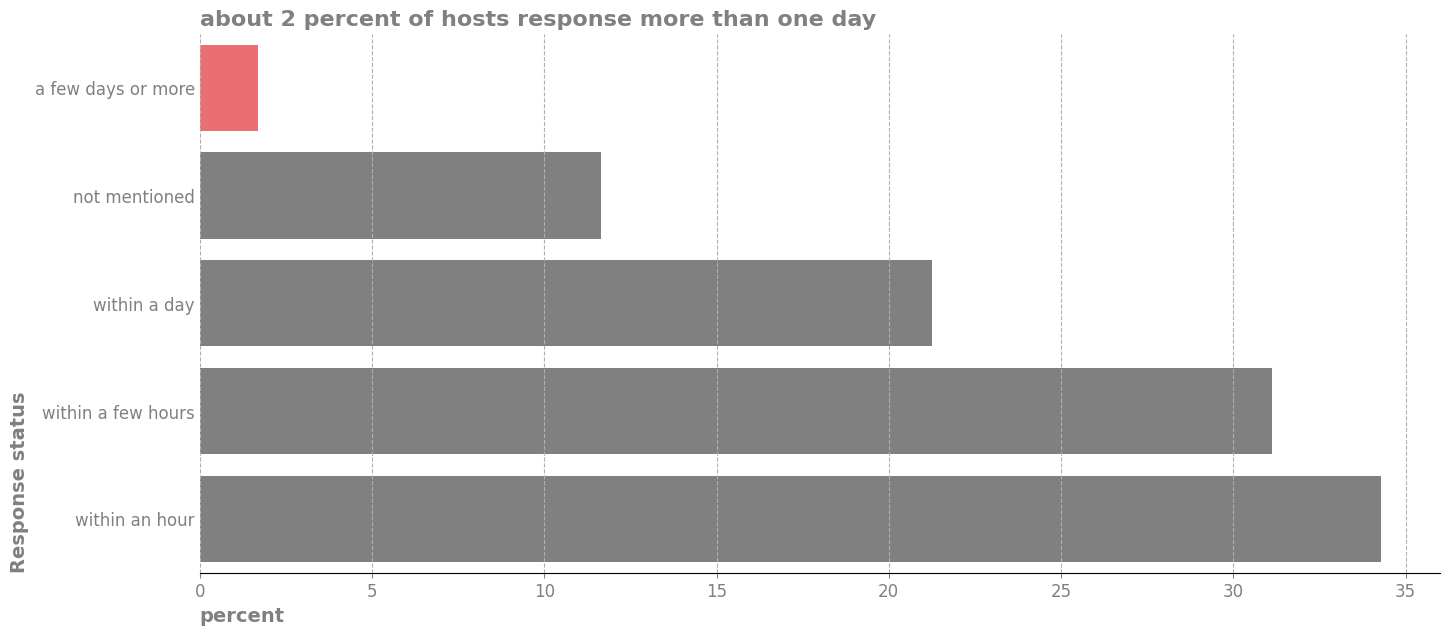

In [10]:
fig,ax=plt.subplots(figsize=(16,7))
sns.barplot(data=host_response_time, y='host_response_time',
                                    x='proportion',
                                    hue='host_response_time',
                                    ax=ax,
                                    palette=['#FF5A5F','#808080','#808080','#808080','#808080'])
ax.spines[['right','top','left']].set_visible(False)
ax.set_title('about 2 percent of hosts response more than one day',loc='left',weight='bold',color='gray',fontsize=16)
ax.set_xlabel('percent',loc='left',weight='bold',color='gray',fontsize=14)
ax.set_ylabel('Response status',loc='bottom', weight='bold',color='gray', fontsize=14)
ax.tick_params(axis='both',colors='gray',labelsize='large')
ax.tick_params(axis='y',which='major',length=0)
ax.grid(axis='x',linestyle='dashed')
plt.show()

In [11]:
airbnb_selected_data=airbnb_selected_data.assign(price=lambda df:df['price']
                                                .str.replace('$','')
                                                .str.replace('.00','')
                                                .str.replace(',','')
                                                .astype('float'))

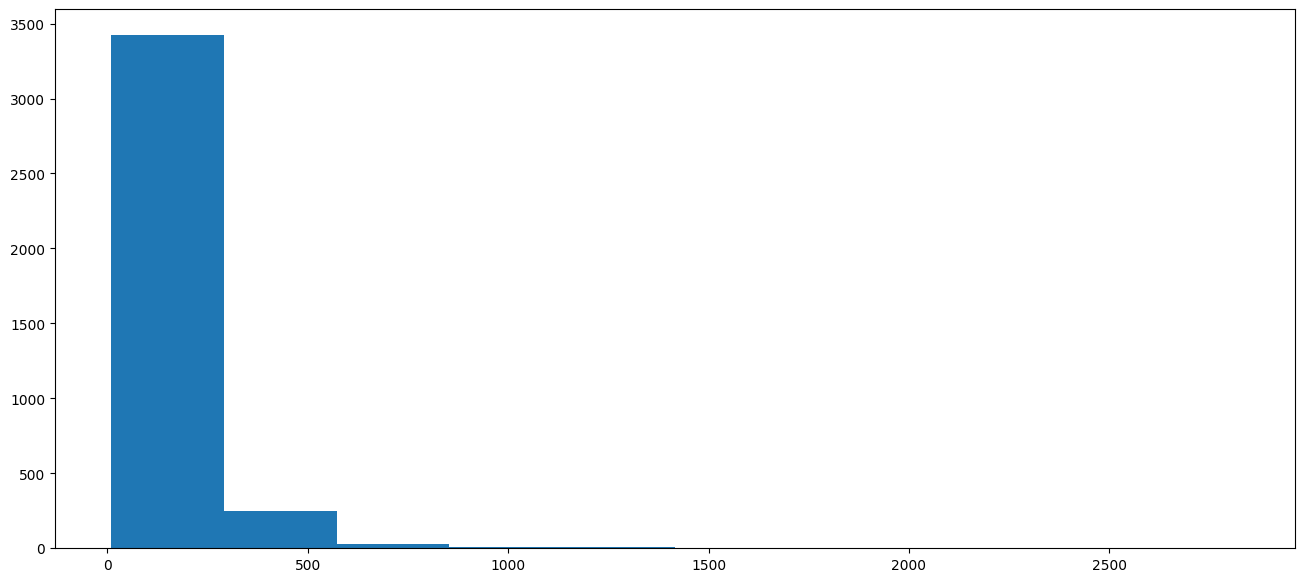

In [12]:
fig,ax=plt.subplots(figsize=(16,7))
ax.hist(airbnb_selected_data['price'])
plt.show()

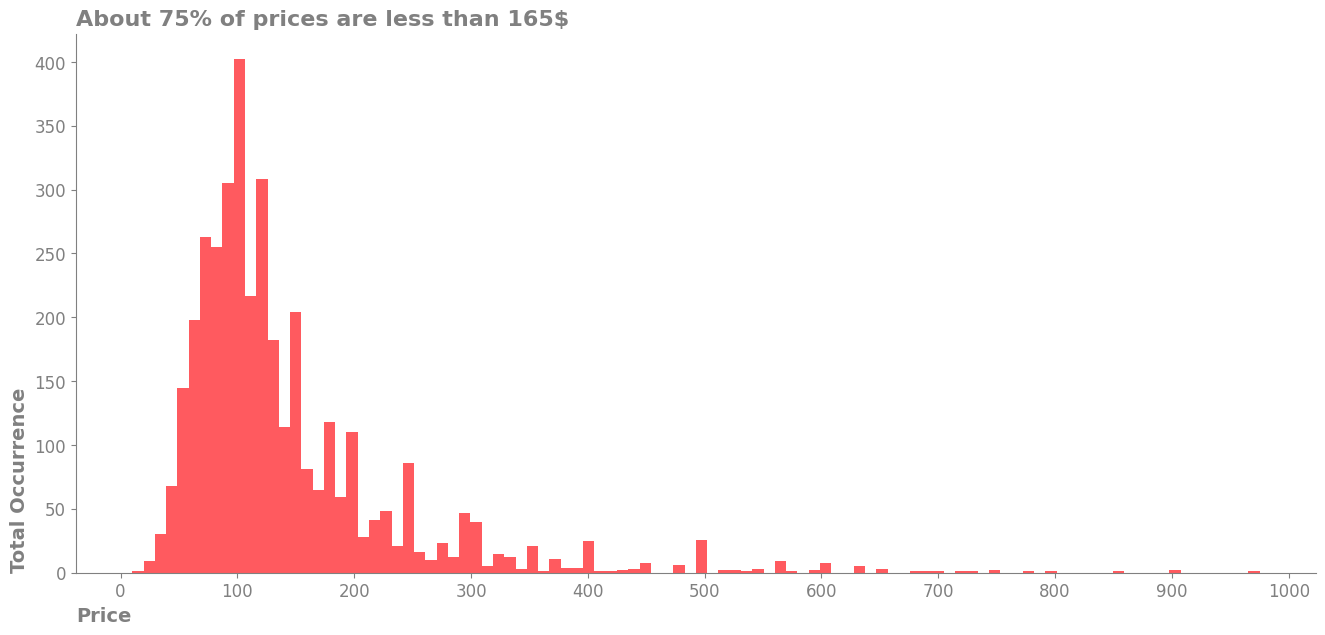

In [13]:
fig,ax=plt.subplots(figsize=(16,7))
ax.hist(airbnb_selected_data.query('price< 1000')['price'],
                            bins=100,
                            color='#FF5A5F'
)
ax.spines[['top','right']].set_visible(False)
ax.spines[['left','bottom']].set_color('gray')
ax.set_title('About 75% of prices are less than 165$',loc='left',weight='bold',color='gray',fontsize=16)
ax.set_xlabel('Price',loc='left',weight='bold',color='gray',fontsize=14)
ax.set_ylabel('Total Occurrence',loc='bottom',weight='bold',color='gray',fontsize=14)
ax.tick_params(axis='both',colors='gray',labelsize='large')
ax.set_xticks(ticks=range(0,1100,100),labels=range(0,1100,100))
plt.show()

In [14]:
airbnb_selected_data['price'].describe()

count    3723.000000
mean      149.165995
std       140.110699
min        10.000000
25%        85.000000
50%       115.000000
75%       165.000000
max      2822.000000
Name: price, dtype: float64

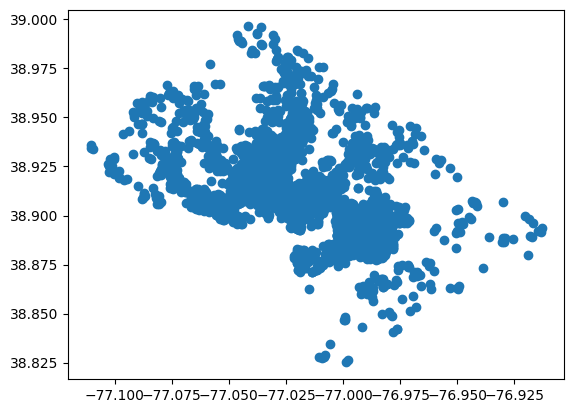

In [15]:
plt.scatter(x=airbnb_selected_data['longitude'], y=airbnb_selected_data['latitude'])
plt.show()

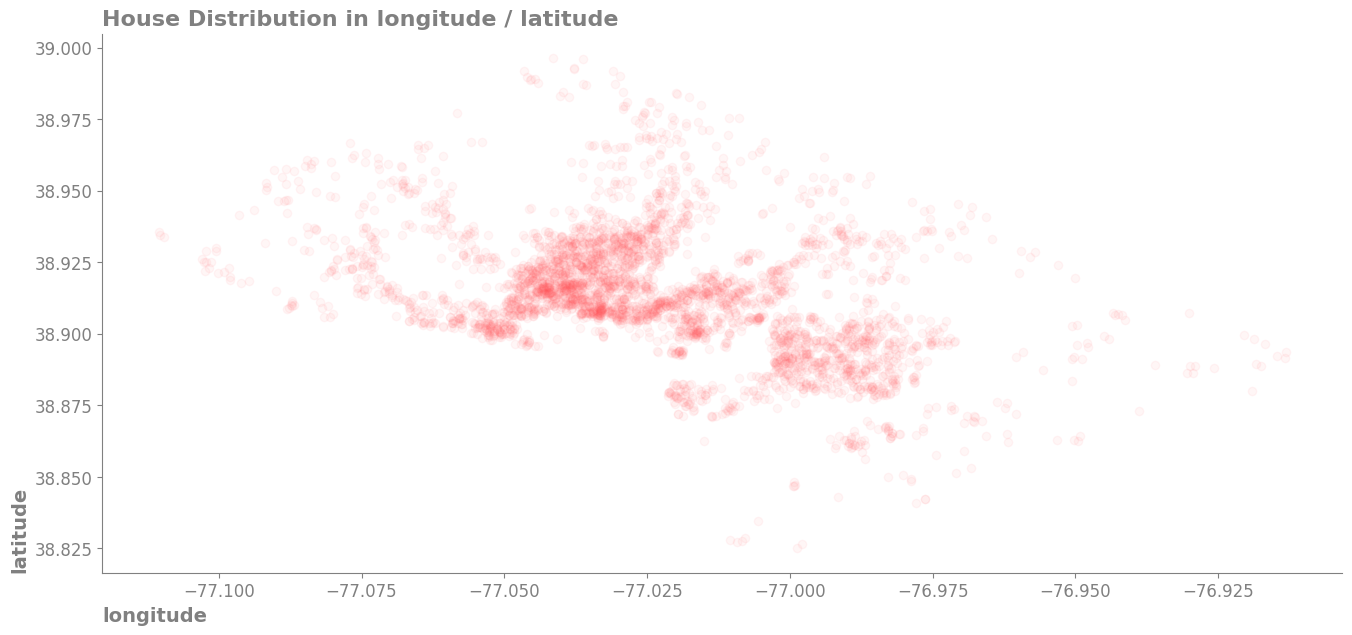

In [16]:
fig,ax=plt.subplots(figsize=(16,7))
ax.scatter(x=airbnb_selected_data['longitude'],
            y=airbnb_selected_data['latitude'],
            alpha=0.05,
            c='#FF5A5F')
ax.spines[['top','right']].set_visible(False)
ax.spines[['left','bottom']].set_color('gray')
ax.set_title('House Distribution in longitude / latitude',loc='left',weight='bold',color='gray',fontsize=16)
ax.set_xlabel('longitude',loc='left',weight='bold',color='gray',fontsize=14)
ax.set_ylabel('latitude',loc='bottom',weight='bold',color='gray',fontsize=14)
ax.tick_params(axis='both',colors='gray',labelsize='large')
plt.show()

In [17]:
neighbourhood_beds_dataframe=pd.pivot_table(data=airbnb_selected_data,index='host_response_time',columns='beds',values='price',aggfunc='mean',fill_value=0)

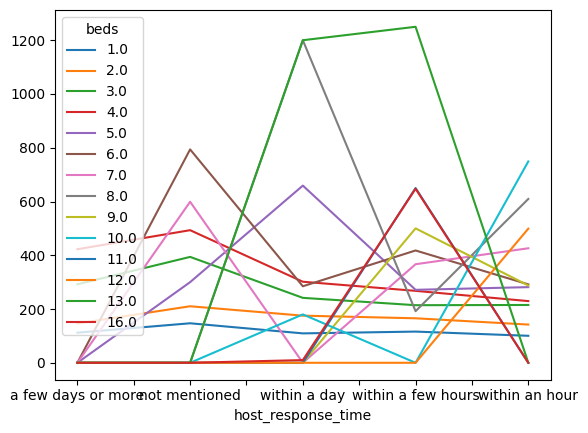

In [18]:
neighbourhood_beds_dataframe.plot()
plt.show()

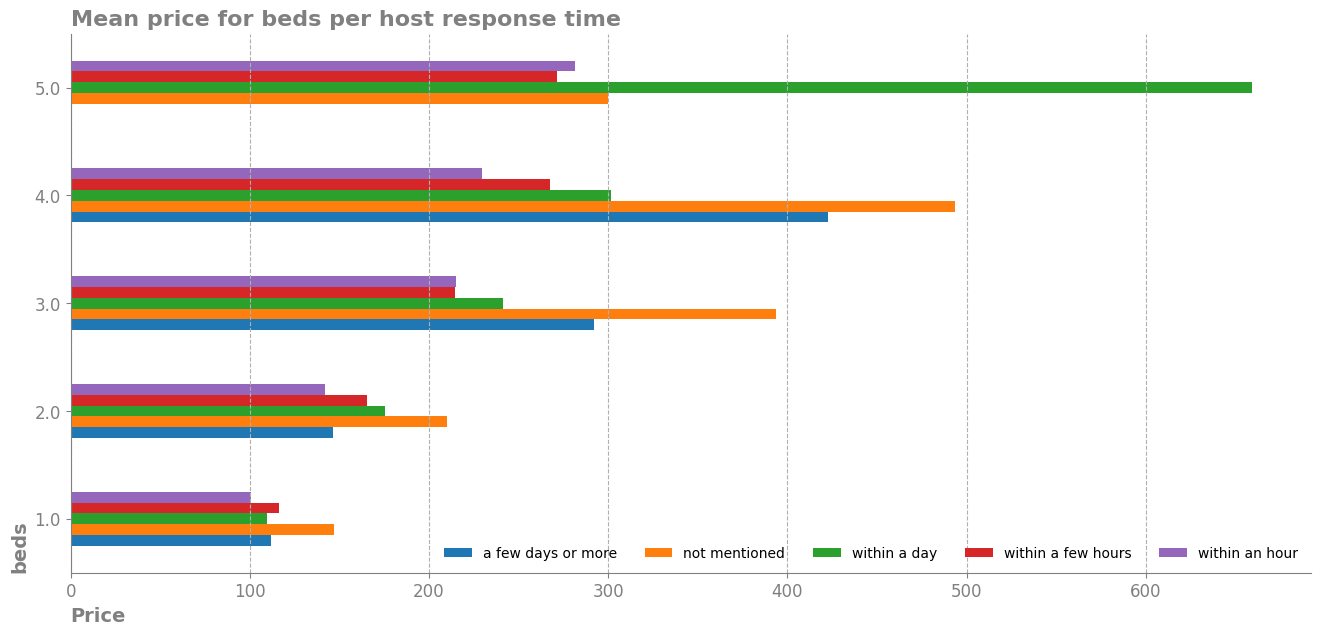

In [19]:
fig, ax= plt.subplots(figsize=(16,7))
neighbourhood_beds_dataframe.loc[:,:5].T.plot(kind='barh',ax=ax)
ax.spines[['top','right']].set_visible(False)
ax.spines[['left','bottom']].set_color('gray')
ax.set_title("Mean price for beds per host response time",loc='left',weight='bold',color='gray',fontsize=16)
ax.set_xlabel('Price',loc='left',weight='bold',color='gray',fontsize=14)
ax.set_ylabel('beds',loc='bottom',weight='bold',color='gray',fontsize=14)
ax.tick_params(axis='both',colors='gray',labelsize='large')
ax.legend(ncols=5,loc='lower right',frameon=False)
ax.grid(axis='x',linestyle='dashed')
plt.show()